In [ ]:
!pip install ipython-autotime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 12.5 MB/s eta 0:00:00


In [ ]:
%load_ext autotime

time: 345 µs (started: 2024-12-06 08:57:17 +00:00)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

time: 589 µs (started: 2024-12-06 08:57:17 +00:00)


In [ ]:
def RungeKuttaCoupled(t, y0, dt, dy0dt):

    k0 = dt*dy0dt(t, y0)

    h0 = dt*dy0dt(t+dt/2., y0+k0/2.)

    L0 = dt*dy0dt(t+dt/2., y0+h0/2.)

    s0 = dt*dy0dt(t+dt, y0+L0)

    y0 = y0 + 1./6.*(k0+2*h0+2*L0+s0)

    t = t + dt

    return t, y0

time: 899 µs (started: 2024-12-06 08:57:17 +00:00)


In [ ]:
def dy0dt(t, y0):
    return y0*(0.025-0.002*y0)


t0 = 0
y0_0 = 6.084
dt = np.linspace(0,100,300)[1]-np.linspace(0,100,300)[0]
t_end = 100

time: 5.42 ms (started: 2024-12-06 08:57:17 +00:00)


In [ ]:
t_list = [t0]
y0_list = [y0_0]

t = t0
y0 = y0_0

from time import time
time0=time()
while t <= t_end:

    t, y0= RungeKuttaCoupled(t, y0, dt, dy0dt)

    t_list.append(t)
    y0_list.append(y0)

time1=time()

time: 6.11 ms (started: 2024-12-06 08:57:17 +00:00)


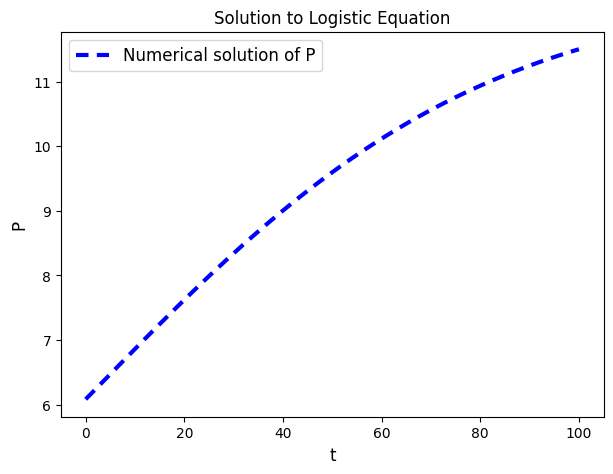

time: 530 ms (started: 2024-12-06 08:57:17 +00:00)


In [ ]:
plt.figure(figsize=(7,5))

plt.plot(t_list, y0_list, label="Numerical solution of P", dashes=(3,2), color="blue",
        lw=3)

plt.legend(loc="best", fontsize=12)
plt.title(r"Solution to Logistic Equation")
plt.xlabel("t", fontsize=12)
plt.ylabel("P", fontsize=12)
plt.show()

In [ ]:
#Training dataset
t = np.linspace(0,100,1022)

x_analytical = y0_list

time: 873 µs (started: 2024-12-06 08:57:18 +00:00)


In [ ]:
import tensorflow as tf

class PINN(tf.keras.Model):
    def __init__(self):
        super(PINN,self).__init__()
        self.dense1= tf.keras.layers.Dense(32, activation = 'silu')
        self.dense2= tf.keras.layers.Dense(16, activation = 'silu')
        self.dense3= tf.keras.layers.Dense(8, activation = 'silu')
        self.dense4= tf.keras.layers.Dense(1, activation = None)

    def call(self,t):
        t=self.dense1(t)
        t=self.dense2(t)
        t=self.dense3(t)
        return self.dense4(t)

time: 9.86 s (started: 2024-12-06 08:57:18 +00:00)


In [ ]:
def loss_fn(model,t):
    with tf.GradientTape() as tape1, tf.GradientTape() as tape2:
        tape1.watch(t)
        output=model(t)
        x=output[:,0:1]
        dxdt = tape1.gradient(x,t)
        #Formula
        res_x = dxdt-x*(0.025-0.002*x)
        #Initial Value
        init_loss_x = tf.square(x[0]-6.084)
        loss = tf.reduce_mean(tf.square(res_x))  + init_loss_x
    return loss

time: 12.5 ms (started: 2024-12-06 08:57:28 +00:00)


In [ ]:
def train(model,t,epos,optimizer):
    for epo in range (epos):
        with tf.GradientTape() as tape:
            loss = loss_fn(model, t)
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        if epo%500 ==0:
            print(f'Epoch{epo}: Loss = {loss.numpy()}')

time: 4.02 ms (started: 2024-12-06 08:57:28 +00:00)


In [ ]:
model = PINN()
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

time: 207 ms (started: 2024-12-06 08:57:28 +00:00)


In [ ]:
t = tf.convert_to_tensor(np.linspace(0,100,1022)[:,None],dtype=tf.float32)

time: 11.4 ms (started: 2024-12-06 08:57:29 +00:00)


In [ ]:
train(model,t,epos = 4000,optimizer = optimizer)

Epoch0: Loss = [37.0553]
Epoch500: Loss = [4.949443e-05]
Epoch1000: Loss = [2.7621674e-05]
Epoch1500: Loss = [2.8755674e-05]
Epoch2000: Loss = [8.3847466e-05]
Epoch2500: Loss = [8.6717155e-06]
Epoch3000: Loss = [3.6281228e-05]
Epoch3500: Loss = [4.2674015e-05]
time: 5min (started: 2024-12-06 08:57:29 +00:00)


In [ ]:
t_test = np.linspace(0,100,300)[:,None]
x_pred = model(t_test).numpy()
x_pred = np.reshape(x_pred, (-1))

time: 12.5 ms (started: 2024-12-06 09:02:30 +00:00)


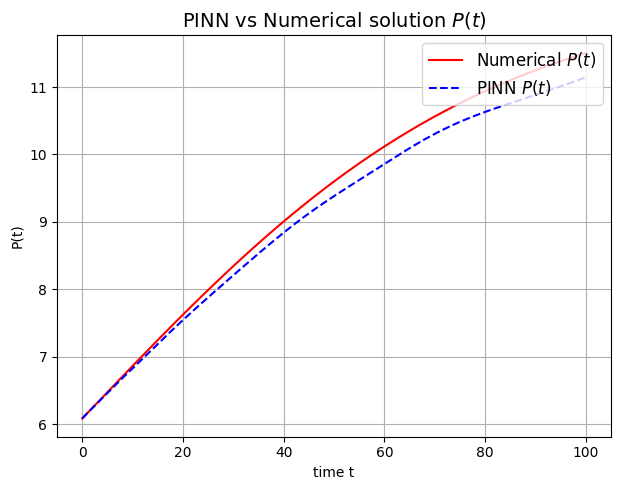

time: 434 ms (started: 2024-12-06 09:02:30 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list[0:]),np.array((y0_list))[0:],label ="Numerical $P(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $P(t)$",color='blue')
plt.title(r'PINN vs Numerical solution $P(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'P(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")


#True Value

plt.tight_layout()
plt.show()

In [ ]:
#L2 loss for PINN
np.sum((np.abs(np.array((y0_list))[0:]-x_pred)**2))/300

0.053152886803870494

time: 8.9 ms (started: 2024-12-06 09:02:30 +00:00)


In [ ]:
#Neurodiffeq

time: 344 µs (started: 2024-12-06 09:02:30 +00:00)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

time: 551 µs (started: 2024-12-06 09:02:30 +00:00)


In [ ]:
!pip install neurodiffeq
from neurodiffeq import diff

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 8.2 MB/s eta 0:00:00
  Created wheel for neurodiffeq: filename=neurodiffeq-0.6.3-py3-none-any.whl size=132419 sha256=01d9a7d95bd8ed35c7650888f8dfd77b71c025f872c624968c6d7bdb75ed345d
  Stored in directory: /root/.cache/pip/wheels/f6/e7/71/84c06f693bbf2ffd52a7c5ecd416c2a2ac053569b283171ddf
Successfully built neurodiffeq
time: 19.1 s (started: 2024-12-06 09:02:30 +00:00)


In [ ]:
from neurodiffeq import diff      # the differentiation operation
from neurodiffeq.ode import solve # the ANN-based solver
from neurodiffeq.conditions import IVP   # the initial condition
from neurodiffeq.monitors import Monitor1D

time: 558 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
from neurodiffeq.ode import solve_system

time: 493 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
import torch

time: 476 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
from neurodiffeq.networks import FCNN # fully-connect neural network
import torch.nn as nn                 # PyTorch neural network module

time: 589 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
from neurodiffeq.generators import Generator1D

time: 470 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

time: 594 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
from neurodiffeq.neurodiffeq import safe_diff as diff
from neurodiffeq.ode import solve, solve_system

time: 535 µs (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
net_ho = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(32,),
    actv=nn.SiLU

)

net_ho_1 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(16 ,),
    actv=nn.SiLU

)

net_ho_2 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(8,),
    actv=nn.SiLU

)


net_ho_3 = FCNN(
    n_input_units=1,
    n_output_units=1,
)

time: 46.1 ms (started: 2024-12-06 09:02:49 +00:00)


/usr/local/lib/python3.10/dist-packages/neurodiffeq/ode.py:260: FutureWarning: The `solve_system` function is deprecated, use a `neurodiffeq.solvers.Solver1D` instance instead
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/neurodiffeq/solvers.py:469: UserWarning: Passing `monitor` is deprecated, use a MonitorCallback and pass a list of callbacks instead
  warnings.warn("Passing `monitor` is deprecated, "


Training Progress:   0%|          | 0/4000 [00:00<?, ?it/s]

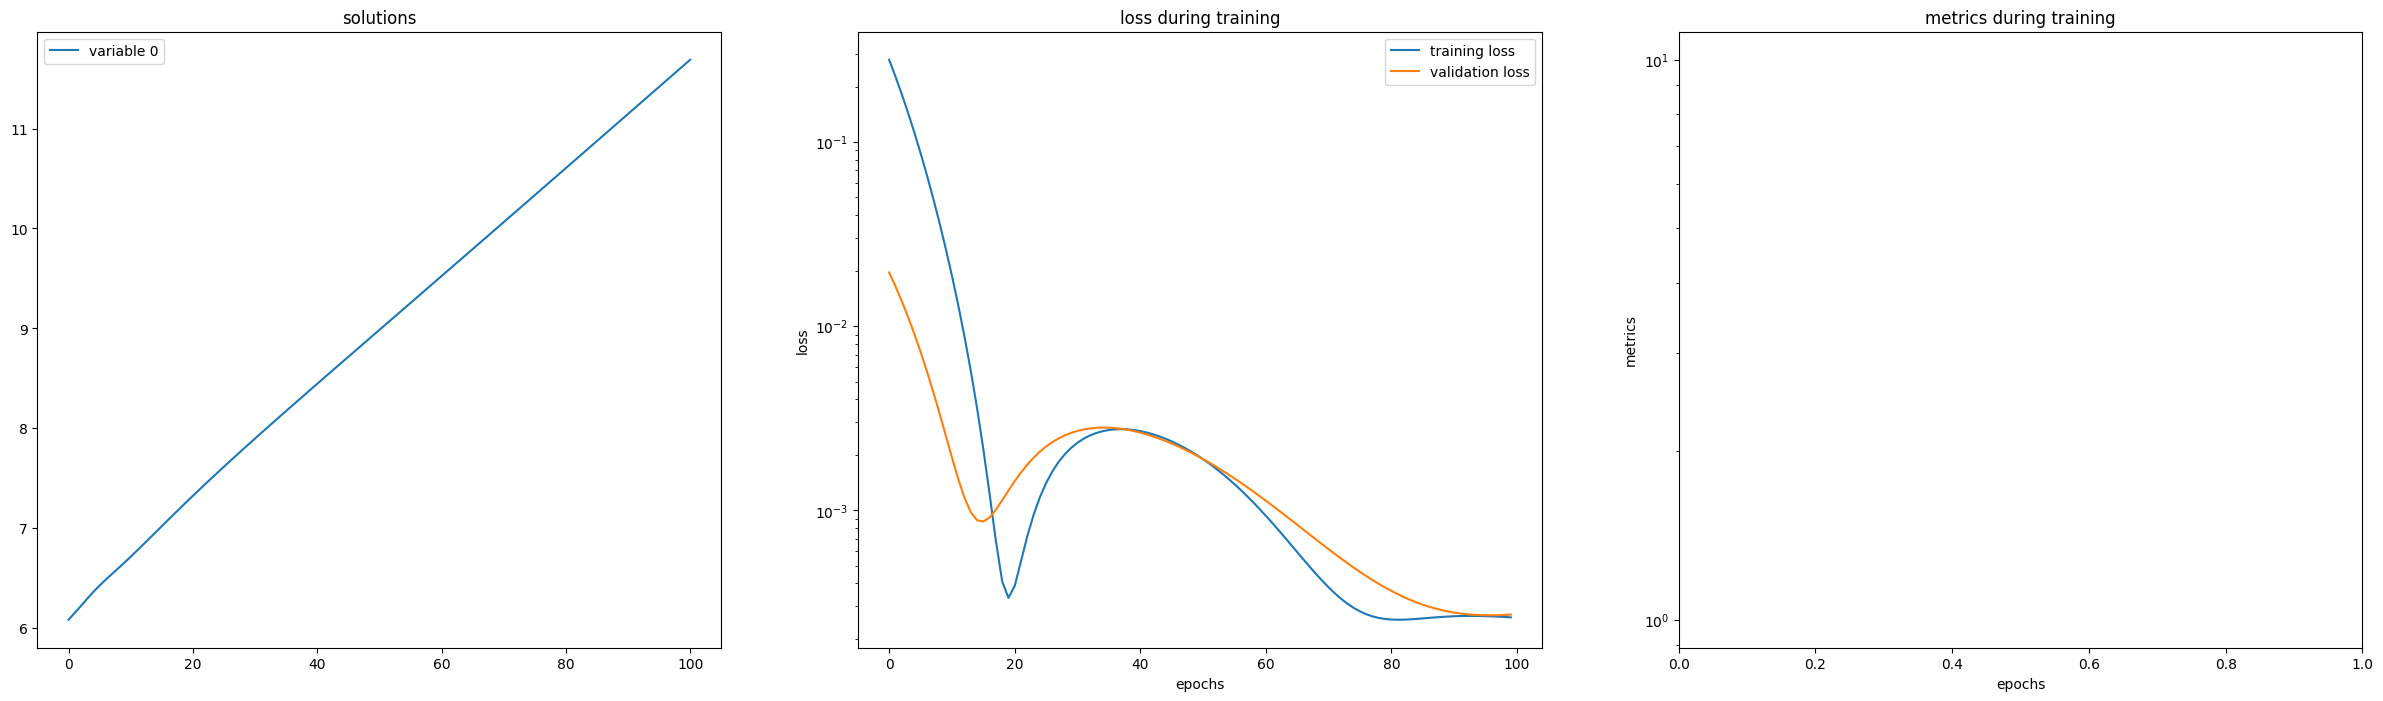

time: 1min 34s (started: 2024-12-06 09:02:49 +00:00)


In [ ]:
# specify the ODE system
la=0.02
mu=0.0202

queueing_theory_equation = lambda y0, t : [diff(y0, t)-y0*(0.025-0.002*y0)


                                                               ]
# specify the initial conditions
init_vals_pc = [
    IVP(t_0=0.0, u_0=6.084),

]
train_gen=Generator1D(size=1022,  t_min=0.0, t_max=100, method='equally-spaced')
# solve the ODE system
solution_pc, _, internal = solve_system(
    ode_system=queueing_theory_equation, conditions=init_vals_pc, t_min=0, t_max=12,
    train_generator=train_gen,
    max_epochs=4000,
    monitor=Monitor1D(t_min=0, t_max=100, check_every=100), return_internal=True,
    nets=[net_ho, net_ho_1, net_ho_2, net_ho_3],
)

In [ ]:
internal

{'nets': [FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=32, bias=True)
      (1): SiLU()
      (2): Linear(in_features=32, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=16, bias=True)
      (1): SiLU()
      (2): Linear(in_features=16, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=8, bias=True)
      (1): SiLU()
      (2): Linear(in_features=8, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=32, bias=True)
      (1): Tanh()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): Tanh()
      (4): Linear(in_features=32, out_features=1, bias=True)
    )
  )],
 'conditions': [<neurodiffeq.conditions.IVP at 0x7fb99fcc0c10>],
 'train_generator': SamplerGenerator(size=1022, generator=Generator1D(size=1022, t_min=0.0, t_max=100, method='equally-space

time: 4.14 ms (started: 2024-12-06 09:04:24 +00:00)


In [ ]:
from time import time
time0=time()
ts = np.linspace(0, 100, 300)
u_net = solution_pc(ts, to_numpy=True)
time1=time()

time: 4.04 ms (started: 2024-12-06 09:04:24 +00:00)


In [ ]:
time=time1-time0
time

0.0032930374145507812

time: 3.74 ms (started: 2024-12-06 09:04:24 +00:00)


In [ ]:
#L2 loss
np.sum(np.abs(np.array((y0_list))[0:]-u_net)**2)/300

5.0037768376697706e-05

time: 3.41 ms (started: 2024-12-06 09:04:24 +00:00)


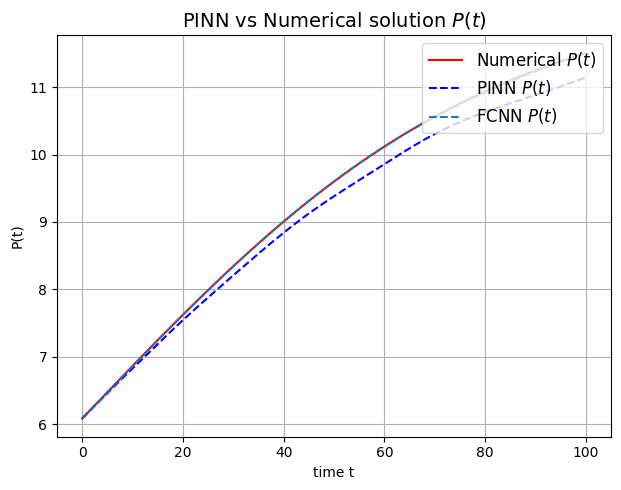

time: 329 ms (started: 2024-12-06 09:04:24 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y0_list))[0:-1],label ="Numerical $P(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $P(t)$",color='blue')
plt.plot(t_test,u_net[0],'--',label ="FCNN $P(t)$")
plt.title(r'PINN vs Numerical solution $P(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'P(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")
plt.tight_layout()
plt.show()

In [ ]:
!pip install deepxde

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.4/184.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 7.6 MB/s eta 0:00:00
time: 11.4 s (started: 2024-12-06 09:04:24 +00:00)


In [ ]:
import deepxde as dde
import matplotlib.pyplot as plt

No backend selected.
Finding available backend...
Found tensorflow.compat.v1


Using backend: tensorflow.compat.v1
Other supported backends: tensorflow, pytorch, jax, paddle.
paddle supports more examples now and is recommended.
Instructions for updating:
non-resource variables are not supported in the long term


Setting the default backend to "tensorflow.compat.v1". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)
time: 5.15 s (started: 2024-12-06 09:04:36 +00:00)


In [ ]:
import numpy as np

time: 539 µs (started: 2024-12-06 09:04:41 +00:00)


In [ ]:
# Define the time domain:
T = 100
num_samples = 1022
num_boundary = 8

# Defining parameters:
alpha = 0.025
beta = 0.002

# Set initial values:
x0 = 6.084

time: 879 µs (started: 2024-12-06 09:04:41 +00:00)


In [ ]:
# Define the ODE-system:
def ode_system(input, output):

    # Get the outputs:
    x = output[:, 0:1]

    # Get the derivatives:
    dx_t = dde.grad.jacobian(output, input, i=0)

    # Return the equations:
    return [
        dx_t - x*(alpha-beta*x),
    ]
# Define the time domain of the ODE:
geom = dde.geometry.TimeDomain(0.0, T)

# Function for determening if x on boundary or not:
def boundary(_, on_initial):
    return on_initial

# Set the intial values:
ic1 = dde.IC(geom, lambda X: x0, boundary, component=0)
# Create the equation:
data = dde.data.PDE(geom, ode_system, [ic1], num_samples, num_boundary, num_test=300)
# Define and create the neural network:
layer_size = [1] +[32]+[16]+ [8]+ [1]
activation = "Swish"
initializer = "Glorot normal"
net = dde.maps.FNN(layer_size, activation, initializer)
# Combine the data and network into a model:
model = dde.Model(data, net)
# Training:
model.compile("adam", lr=0.01, loss_weights= [10, 0.0001])
losshistory, train_state = model.train(epochs=4000, display_every= 1000)

#model.compile("L-BFGS")
#losshistory, train_state = model.train()

Compiling model...
Building feed-forward neural network...
'build' took 0.169987 s

'compile' took 1.080839 s

Training model...

Step      Train loss              Test loss               Test metric
0         [1.12e-02, 3.70e-03]    [1.13e-02, 3.70e-03]    []  
1000      [9.48e-05, 5.21e-08]    [9.41e-05, 5.21e-08]    []  
2000      [4.72e-06, 8.07e-09]    [4.75e-06, 8.07e-09]    []  
3000      [2.03e-05, 4.50e-09]    [2.03e-05, 4.50e-09]    []  
4000      [6.56e-05, 6.77e-08]    [6.53e-05, 6.77e-08]    []  

Best model at step 2000:
  train loss: 4.73e-06
  test loss: 4.76e-06
  test metric: []

'train' took 22.091604 s

time: 23.2 s (started: 2024-12-06 09:04:41 +00:00)


Compiling model...
'compile' took 0.980131 s

Training model...

Step      Train loss              Test loss               Test metric
4000      [6.56e-06, 6.77e-04]    [6.53e-06, 6.77e-04]    []  
4016      [6.56e-06, 6.77e-04]    [6.53e-06, 6.77e-04]    []  

Best model at step 2000:
  train loss: 4.73e-06
  test loss: 4.76e-06
  test metric: []

'train' took 2.072556 s



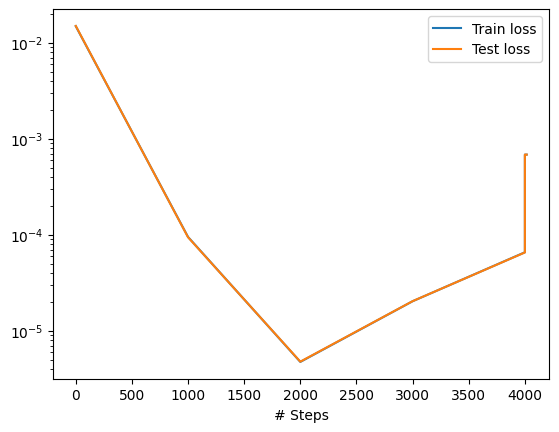

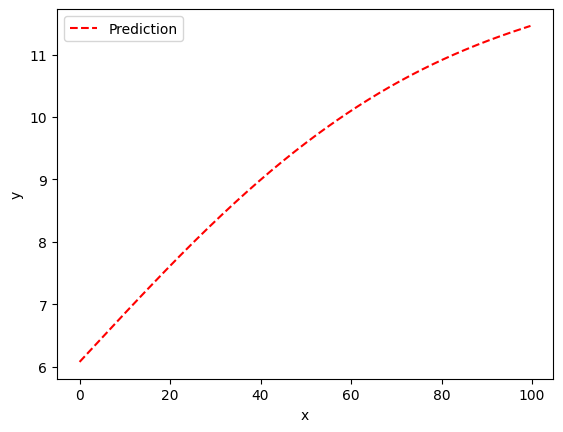

time: 4.54 s (started: 2024-12-06 09:05:04 +00:00)


In [ ]:
model.compile("L-BFGS")
losshistory, train_state = model.train()
# Plot and save:
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

In [ ]:
x=model.predict(np.expand_dims(np.linspace(0,100,300),axis=-1))[:,0]

time: 33.3 ms (started: 2024-12-06 09:05:09 +00:00)


In [ ]:
t=np.linspace(0,100,300)

time: 532 µs (started: 2024-12-06 09:05:09 +00:00)


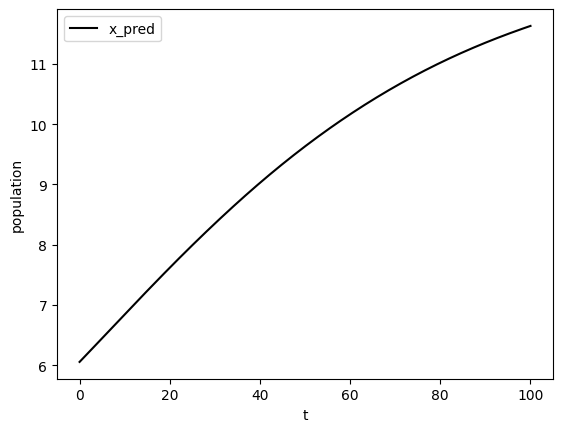

time: 224 ms (started: 2024-12-06 09:05:09 +00:00)


In [ ]:
# Plot the two solutions in the same plot:
t = t.reshape(300, 1)
sol_pred = model.predict(t)
x_pred_DDE = sol_pred[:, 0:1]

plt.xlabel("t")
plt.ylabel("population")
plt.plot(t, x_pred_DDE, color="black", label="x_pred")
#plt.plot(t, x_true, color="black", label="x_true", linestyle="dashed")
#plt.plot(t, y_true, color="blue", label="y_true", linestyle="dashed")
plt.legend()
plt.show()

#print("L2 relative error for x:", dde.metrics.l2_relative_error(x_true, x_pred))
#print("L2 relative error for y:", dde.metrics.l2_relative_error(y_true, y_pred))

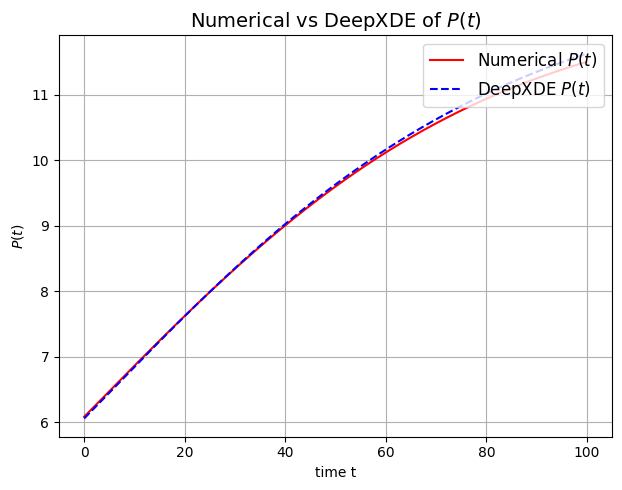

time: 322 ms (started: 2024-12-06 09:05:09 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list),np.array(y0_list),label ="Numerical $P(t)$",color='red')
plt.plot(np.linspace(0,100,300),x,'--',label ="DeepXDE $P(t)$",color='blue')
plt.title(r'Numerical vs DeepXDE of $P(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$P(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")


plt.tight_layout()
plt.show()

In [ ]:
#L2 loss
np.sum(np.abs(np.array((y0_list))[0:]-x)**2)/300

0.0031875346529770666

time: 3.84 ms (started: 2024-12-06 09:05:09 +00:00)


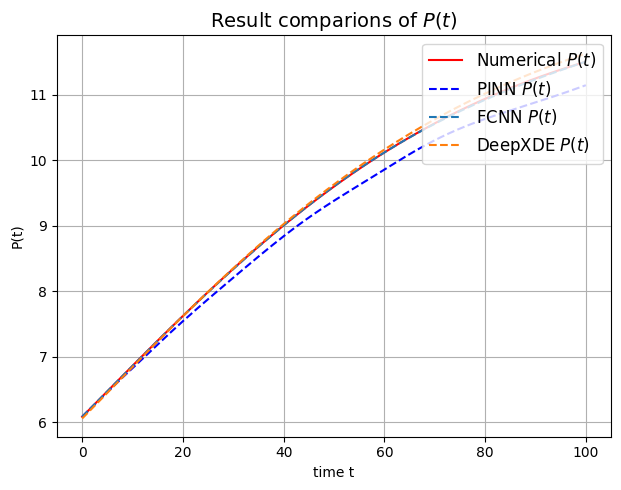

time: 1.04 s (started: 2024-12-06 09:07:14 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y0_list))[0:-1],label ="Numerical $P(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $P(t)$",color='blue')
plt.plot(t_test,u_net[0],'--',label ="FCNN $P(t)$")
plt.plot(t_test,x,'--',label ="DeepXDE $P(t)$")
plt.title(r'Result comparions of $P(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'P(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")


plt.tight_layout()
plt.show()